In [1]:
!pip install "ray[train,tune,data]"

In [1]:
import os
import logging
import warnings
os.environ["RAY_DEDUP_LOGS"] = "1"
warnings.filterwarnings("ignore")

In [2]:
import ray
from ray import train, tune
from ray.train import ScalingConfig, RunConfig
from ray.train.torch import TorchTrainer

In [3]:
import torch
import torchvision
import torchvision.transforms as transforms

if torch.cuda.is_available():
    device = torch.device("cuda:0")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(device)

cuda:0


Dodaliśmy normalizację naszych danych, aby gradienty były równe, a trening szybszy.
Jako, że nie mamy zbyt wielu danych to robimy ich augumentacje za pomocą RandomCrop oraz RandomHorizontalFlip.
BatchSize to 128 - klasyczny rozmiar dla naszego modelu

Po pierwszych testach naszego modelu dodaliśmy również ColorJitter - odporność na oświetlenie i tło oraz RandomErasing - wymuszanie, aby model nie operał się jedynie na jednym fragmencie, lecz na globalnych cechach.

In [4]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.2), ratio=(0.3, 3.3)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

batch_size = 128

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform_train
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True
)

testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform_test
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=True
)

In [5]:
logging.getLogger("ray").setLevel(logging.ERROR)
logging.getLogger("ray.train").setLevel(logging.ERROR)

if ray.is_initialized():
    ray.shutdown()

ray.init(
    logging_level=logging.ERROR,
    configure_logging=True
)

ray.shutdown()
ray.init(ignore_reinit_error=True)

def cifar_to_ray_dataset(torch_dataset):
    items = []

    for image, label in torch_dataset:
        items.append({
            "image": image.numpy(),
            "label": label,
        })

    return ray.data.from_items(items)

ray_train_ds = cifar_to_ray_dataset(trainset)
ray_test_ds = cifar_to_ray_dataset(testset)

2026-05-31 17:36:40,918	INFO worker.py:2012 -- Started a local Ray instance.


In [6]:
classes = (
"airplane",
"automobile",
"bird",
"cat",
"deer",
"dog",
"frog",
"horse",
"ship",
"truck"
)

print(type(testset[0][0]))

<class 'torch.Tensor'>


CIFAR-10 to zbiór danych do uczenia maszynowego i widzenia komputerowego.
Zawiera 60 000 kolorowych obrazów 32×32 px, podzielonych na 10 klas (m.in. samolot, samochód, ptak, kot, pies).
Standardowo 50 000 obrazów służy do treningu, a 10 000 do testów.

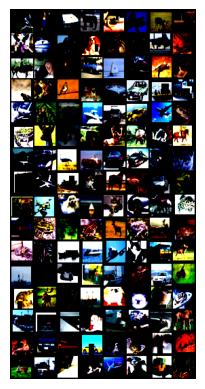

bird       frog       automobile horse      frog       frog       deer       horse     
dog        ship       truck      dog        dog        bird       airplane   frog      
horse      cat        bird       automobile ship       automobile cat        cat       
frog       frog       bird       dog        automobile automobile ship       truck     
airplane   dog        deer       ship       truck      automobile airplane   frog      
frog       deer       cat        bird       deer       deer       dog        horse     
airplane   automobile bird       ship       automobile truck      frog       cat       
horse      airplane   truck      frog       horse      dog        automobile frog      
deer       airplane   dog        ship       cat        automobile deer       frog      
truck      frog       deer       frog       deer       frog       deer       frog      
frog       frog       ship       ship       airplane   cat        truck      deer      
ship       deer       cat       

In [7]:
import matplotlib.pyplot as plt
import numpy as np


def imshow(img):
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()


dataiter = iter(trainloader)
images, labels = next(dataiter)

def grid_show(images, nrow=8):
    imshow(torchvision.utils.make_grid(images, nrow=nrow))


def print_grid(labels, nrow=8):
    rows = [labels[n : n + nrow] for n in range(0, len(labels), nrow)]
    for r in rows:
        print(" ".join(f"{classes[c]:10s}" for c in r))

grid_show(images)
print_grid(labels)


In [8]:
import torch.nn as nn
import torch.nn.functional as F


import torch
import torch.nn as nn
import torch.nn.functional as F

import torch
import torch.nn as nn
from torchvision.models import resnet18

def make_resnet18_cifar(num_classes=10):
    model = resnet18(weights=None)

    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False
    )

    model.maxpool = nn.Identity()

    model.fc = nn.Linear(model.fc.in_features, num_classes)

    return model

In [9]:
net = make_resnet18_cifar()
net = net.to(device)

Liczba epok to 50 - standard.
Dla zmniejszenia overfittingu uzyliśmy Label smoothing (CrossEntropyLoss), model jest dzięki temu mniej pewny siebie.
Dodaliśmy regularyzacje L2 (penalizacja za duże wagi) wraz z AdamW.
Zapewniliśmy malenie lr w czasie za pomocą CosineAnnealingLR.


In [10]:
import torch.optim as optim

epochs = 50
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

net = make_resnet18_cifar().to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

Zastosowaliśmy MixUp dla zwiększenia generalizacji - wygładza on granice decyzyjne

In [11]:
def mixup_data(x, y, alpha=0.2):
    if alpha <= 0:
        return x, y, y, 1.0
    lam = torch.distributions.Beta(alpha, alpha).sample().item()
    idx = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    y_a, y_b = y, y[idx]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b,)

def mixup_correct_count(pred_logits, y_a, y_b, lam):
    pred = pred_logits.argmax(dim=1)
    return (lam * (pred == y_a).float() + (1 - lam) * (pred == y_b).float()).sum().item()

In [12]:
import torch

def train_model(
    net,
    trainloader,
    optimizer,
    criterion,
    device,
    epochs=50,
    scheduler=None,
    mixup_alpha=0.2,
    print_every=1
):
    net.to(device)

    for epoch in range(epochs):
        net.train()
        running_loss = 0.0
        correct_soft = 0.0
        total = 0

        for images, labels in trainloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            if mixup_alpha and mixup_alpha > 0:
                images, y_a, y_b, lam = mixup_data(images, labels, alpha=mixup_alpha)
                outputs = net(images)
                loss = mixup_criterion(criterion, outputs, y_a, y_b, lam)
                correct_soft += mixup_correct_count(outputs, y_a, y_b, lam)
            else:
                outputs = net(images)
                loss = criterion(outputs, labels)
                correct_soft += (outputs.argmax(1) == labels).float().sum().item()

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += labels.size(0)

        if scheduler is not None:
            scheduler.step()

        avg_loss = running_loss / total
        acc_soft = 100.0 * correct_soft / total

        if (epoch + 1) % print_every == 0:
            lr = optimizer.param_groups[0]["lr"]
            print(f"Epoch [{epoch+1}/{epochs}]  loss: {avg_loss:.4f}  acc(soft): {acc_soft:.2f}%  lr: {lr:.6f}")

In [14]:
# train_model(
#     net=net,
#     trainloader=trainloader,
#     optimizer=optimizer,
#     criterion=criterion,
#     device=device,
#     epochs=epochs,
#     scheduler=scheduler,
#     mixup_alpha=0.2
# )

In [36]:
# RAY TRAIN LOOP

from ray import train
from ray.train import torch as ray_torch

def ray_train_loop(config):
    batch_size = config["batch_size"]

    trainloader = torch.utils.data.DataLoader(
        trainset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
    )

    testloader = torch.utils.data.DataLoader(
        testset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    trainloader = ray_torch.prepare_data_loader(trainloader)
    testloader = ray_torch.prepare_data_loader(testloader)

    model = make_resnet18_cifar()
    model = ray_torch.prepare_model(model)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=config["label_smoothing"]
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=config["epochs"],
    )

    for epoch in range(config["epochs"]):
        model.train()

        running_loss = 0.0
        correct_soft = 0.0
        total = 0

        if train.get_context().get_world_size() > 1:
            trainloader.sampler.set_epoch(epoch)

        for images, labels in trainloader:
            optimizer.zero_grad(set_to_none=True)

            if config["mixup_alpha"] > 0:
                images, y_a, y_b, lam = mixup_data(
                    images,
                    labels,
                    alpha=config["mixup_alpha"],
                )

                outputs = model(images)
                loss = mixup_criterion(
                    criterion,
                    outputs,
                    y_a,
                    y_b,
                    lam,
                )

                correct_soft += mixup_correct_count(
                    outputs,
                    y_a,
                    y_b,
                    lam,
                )
            else:
                outputs = model(images)
                loss = criterion(outputs, labels)

                correct_soft += (
                    outputs.argmax(dim=1) == labels
                ).float().sum().item()

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += labels.size(0)

        scheduler.step()

        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in testloader:
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()
                val_total += labels.size(0)

        train.report(
            {
                "epoch": epoch + 1,
                "train_loss": running_loss / total,
                "train_acc": 100.0 * correct_soft / total,
                "val_loss": val_loss / val_total,
                "val_acc": 100.0 * val_correct / val_total,
            }
        )

In [16]:
ray_config = {
    "epochs": 50,
    "batch_size": 128,
    "lr": 1e-3,
    "weight_decay": 5e-4,
    "label_smoothing": 0.1,
    "mixup_alpha": 0.2,
}

trainer = TorchTrainer(
    train_loop_per_worker=ray_train_loop,
    train_loop_config=ray_config,
    scaling_config=ScalingConfig(
        num_workers=1,
        use_gpu=True
    ),
    run_config=RunConfig(
        name="cifar10_ray_train"
    )
)

result = trainer.fit()

(TrainController pid=42024) Requesting resources: {'GPU': 1} * 1
(TrainController pid=42024) Failed to send resource request for train-c6c70e1670854a3486bc487671ce3a7d. If this only happens transiently during network partition or CPU being overloaded, it's safe to ignore this error. If this error persists, file a GitHub issue.
(TrainController pid=42024) Traceback (most recent call last):
(TrainController pid=42024)   File "/usr/local/lib/python3.12/dist-packages/ray/train/v2/_internal/execution/scaling_policy/scaling_policy.py", line 120, in _send_resource_request
(TrainController pid=42024)     ray.get(
(TrainController pid=42024)   File "/usr/local/lib/python3.12/dist-packages/ray/_private/auto_init_hook.py", line 22, in auto_init_wrapper
(TrainController pid=42024)     return fn(*args, **kwargs)
(TrainController pid=42024)            ^^^^^^^^^^^^^^^^^^^
(TrainController pid=42024)   File "/usr/local/lib/python3.12/dist-packages/ray/_private/client_mode_hook.py", line 107, in wrappe

```text
Epoch [1/50]  loss: 1.7891  acc(soft): 41.46%  val_loss: 1.7052  val_acc: 47.77%
Epoch [2/50]  loss: 1.4607  acc(soft): 59.30%  val_loss: 1.2089  val_acc: 68.86%
Epoch [3/50]  loss: 1.3434  acc(soft): 65.35%  val_loss: 1.0901  val_acc: 74.35%
Epoch [4/50]  loss: 1.2813  acc(soft): 68.43%  val_loss: 1.0131  val_acc: 78.44%
Epoch [5/50]  loss: 1.2180  acc(soft): 71.45%  val_loss: 0.9892  val_acc: 80.58%
Epoch [6/50]  loss: 1.1838  acc(soft): 72.76%  val_loss: 0.9195  val_acc: 82.67%
Epoch [7/50]  loss: 1.1573  acc(soft): 73.89%  val_loss: 0.9347  val_acc: 81.66%
Epoch [8/50]  loss: 1.1049  acc(soft): 75.99%  val_loss: 0.8590  val_acc: 85.19%
Epoch [9/50]  loss: 1.0765  acc(soft): 77.32%  val_loss: 0.8897  val_acc: 82.91%
Epoch [10/50]  loss: 1.0529  acc(soft): 78.07%  val_loss: 0.8223  val_acc: 86.48%
Epoch [11/50]  loss: 1.0821  acc(soft): 77.20%  val_loss: 0.8337  val_acc: 86.89%
Epoch [12/50]  loss: 1.0567  acc(soft): 78.29%  val_loss: 0.7919  val_acc: 88.53%
Epoch [13/50]  loss: 1.0221  acc(soft): 79.90%  val_loss: 0.7923  val_acc: 88.20%
Epoch [14/50]  loss: 0.9905  acc(soft): 81.01%  val_loss: 0.8145  val_acc: 86.86%
Epoch [15/50]  loss: 0.9963  acc(soft): 80.95%  val_loss: 0.7590  val_acc: 89.36%
Epoch [16/50]  loss: 0.9839  acc(soft): 81.40%  val_loss: 0.7646  val_acc: 89.77%
Epoch [17/50]  loss: 0.9493  acc(soft): 82.88%  val_loss: 0.7555  val_acc: 89.85%
Epoch [18/50]  loss: 0.9501  acc(soft): 82.77%  val_loss: 0.7497  val_acc: 89.67%
Epoch [19/50]  loss: 0.9365  acc(soft): 83.56%  val_loss: 0.7652  val_acc: 90.21%
Epoch [20/50]  loss: 0.9535  acc(soft): 82.68%  val_loss: 0.7615  val_acc: 90.79%
Epoch [21/50]  loss: 0.9008  acc(soft): 85.04%  val_loss: 0.7160  val_acc: 91.33%
Epoch [22/50]  loss: 0.9233  acc(soft): 84.17%  val_loss: 0.7433  val_acc: 90.47%
Epoch [23/50]  loss: 0.9304  acc(soft): 83.55%  val_loss: 0.7059  val_acc: 91.72%
Epoch [24/50]  loss: 0.9252  acc(soft): 83.92%  val_loss: 0.7259  val_acc: 91.80%
Epoch [25/50]  loss: 0.9047  acc(soft): 85.00%  val_loss: 0.7440  val_acc: 90.71%
Epoch [26/50]  loss: 0.8661  acc(soft): 86.38%  val_loss: 0.6990  val_acc: 92.11%
Epoch [27/50]  loss: 0.8684  acc(soft): 86.52%  val_loss: 0.6981  val_acc: 91.88%
Epoch [28/50]  loss: 0.8671  acc(soft): 86.51%  val_loss: 0.7075  val_acc: 92.22%
Epoch [29/50]  loss: 0.8626  acc(soft): 86.70%  val_loss: 0.7007  val_acc: 92.67%
Epoch [30/50]  loss: 0.8835  acc(soft): 85.78%  val_loss: 0.6812  val_acc: 92.45%
Epoch [31/50]  loss: 0.8487  acc(soft): 87.23%  val_loss: 0.6936  val_acc: 92.34%
Epoch [32/50]  loss: 0.8837  acc(soft): 85.79%  val_loss: 0.6790  val_acc: 92.86%
Epoch [33/50]  loss: 0.8513  acc(soft): 87.00%  val_loss: 0.6722  val_acc: 93.06%
Epoch [34/50]  loss: 0.8710  acc(soft): 86.51%  val_loss: 0.6865  val_acc: 93.28%
Epoch [35/50]  loss: 0.8171  acc(soft): 88.62%  val_loss: 0.6779  val_acc: 93.14%
Epoch [36/50]  loss: 0.8507  acc(soft): 87.45%  val_loss: 0.6800  val_acc: 93.35%
Epoch [37/50]  loss: 0.8342  acc(soft): 87.94%  val_loss: 0.6826  val_acc: 93.20%
Epoch [38/50]  loss: 0.8324  acc(soft): 87.80%  val_loss: 0.6726  val_acc: 93.15%
Epoch [39/50]  loss: 0.8363  acc(soft): 88.01%  val_loss: 0.6617  val_acc: 93.51%
Epoch [40/50]  loss: 0.8244  acc(soft): 88.23%  val_loss: 0.6680  val_acc: 93.86%
Epoch [41/50]  loss: 0.7990  acc(soft): 89.16%  val_loss: 0.6846  val_acc: 93.87%
Epoch [42/50]  loss: 0.8122  acc(soft): 88.89%  val_loss: 0.6682  val_acc: 93.88%
Epoch [43/50]  loss: 0.8339  acc(soft): 87.94%  val_loss: 0.6764  val_acc: 93.80%
Epoch [44/50]  loss: 0.7931  acc(soft): 89.59%  val_loss: 0.6693  val_acc: 93.85%
Epoch [45/50]  loss: 0.8224  acc(soft): 88.30%  val_loss: 0.6586  val_acc: 93.96%
Epoch [46/50]  loss: 0.8423  acc(soft): 87.29%  val_loss: 0.6682  val_acc: 93.83%
Epoch [47/50]  loss: 0.8347  acc(soft): 87.87%  val_loss: 0.6879  val_acc: 93.80%
Epoch [48/50]  loss: 0.8231  acc(soft): 88.49%  val_loss: 0.6887  val_acc: 93.88%
Epoch [49/50]  loss: 0.8383  acc(soft): 87.64%  val_loss: 0.6706  val_acc: 93.93%
Epoch [50/50]  loss: 0.8065  acc(soft): 88.99%  val_loss: 0.6595  val_acc: 94.00%
```


